# Machine Learning - Lab 4
## Perceptron and Classical Machine Learning

In [48]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

### 2.1 Supplied image files and how to read them
- Red pixels `(255, 0, 0)` -> class `y = -1`
- Blue pixels `(0, 0, 255)` -> class `y = +1`
- White background is ignored
- Coordinates are `x = (x1, x2) = (column, row)`

In [49]:
def load_bmp(path):
    arr = np.asarray(Image.open(path).convert('RGB'))
    h, w, _ = arr.shape

    # Red: y = -1, Blue: y = +1
    red = np.where((arr[:, :, 0] == 255) & (arr[:, :, 1] == 0) & (arr[:, :, 2] == 0))
    blue = np.where((arr[:, :, 0] == 0) & (arr[:, :, 1] == 0) & (arr[:, :, 2] == 255))

    # Observation: x = (col, row)
    X_red = np.column_stack([red[1], red[0]])
    X_blue = np.column_stack([blue[1], blue[0]])

    X = np.vstack([X_red, X_blue])
    y = np.concatenate([-np.ones(len(X_red), int), np.ones(len(X_blue), int)])
    return X, y, (w, h)

#### Checkpoint D0 Verification
Verify dimensions and pixel counts match the lab guide:
- `test01.bmp`: 73 x 67, 14 red, 11 blue
- `test06.bmp`: 287 x 258, 1074 red, 1564 blue
- `test07.bmp`: 420 x 320, 629 red, 629 blue

In [50]:
for name in ['test01.bmp', 'test06.bmp', 'test07.bmp']:
    path = os.path.join('data', name) if os.path.exists(os.path.join('data', name)) else name
    X, y, (w, h) = load_bmp(path)
    print(f"{name}: {w}x{h}, red={np.sum(y == -1)}, blue={np.sum(y == 1)}")

test01.bmp: 73x67, red=14, blue=11
test06.bmp: 287x258, red=1074, blue=1564
test07.bmp: 420x320, red=629, blue=629


#### Plot extracted pixel coordinates

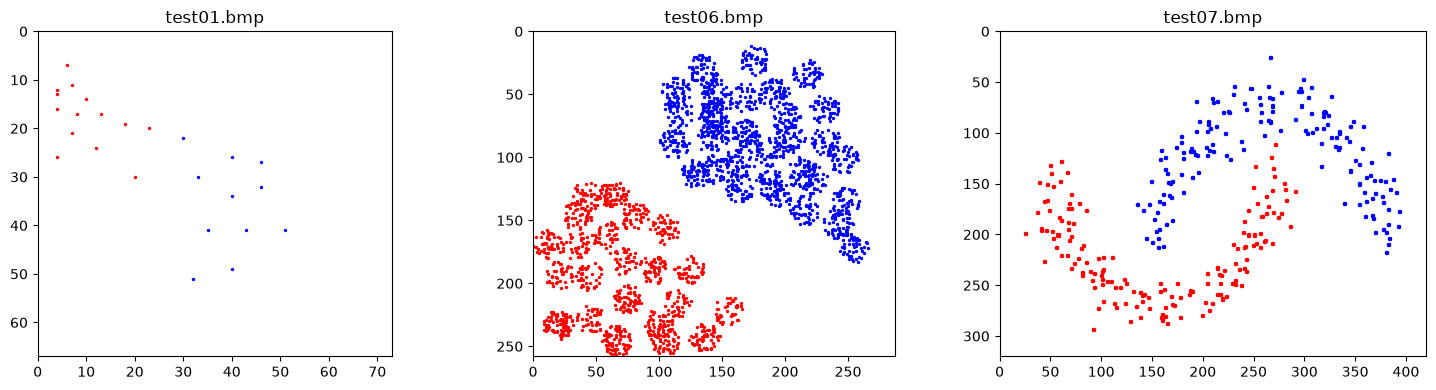

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ['test01.bmp', 'test06.bmp', 'test07.bmp']):
    path = os.path.join('data', name) if os.path.exists(os.path.join('data', name)) else name
    X, y, (w, h) = load_bmp(path)
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c='red', s=2, label='Red (-1)')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c='blue', s=2, label='Blue (+1)')
    ax.set_xlim(0, w)
    ax.set_ylim(h, 0)  # Invert vertical axis to match image coordinates
    ax.set_title(name)
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

### 2.2 A small numerical example for debugging
8 linearly separable points used for deterministic debugging before images.

In [52]:
def get_toy_data():
    X = np.array([
        [2, 1], [1, 2], [2, 2], [3, 1],
        [-2, -1], [-1, -2], [-2, -2], [-3, -1]
    ], float)
    y = np.array([1, 1, 1, 1, -1, -1, -1, -1])
    return X, y

X_toy, y_toy = get_toy_data()
print('X:\n', X_toy)
print('y:\n', y_toy)

X:
 [[ 2.  1.]
 [ 1.  2.]
 [ 2.  2.]
 [ 3.  1.]
 [-2. -1.]
 [-1. -2.]
 [-2. -2.]
 [-3. -1.]]
y:
 [ 1  1  1  1 -1 -1 -1 -1]


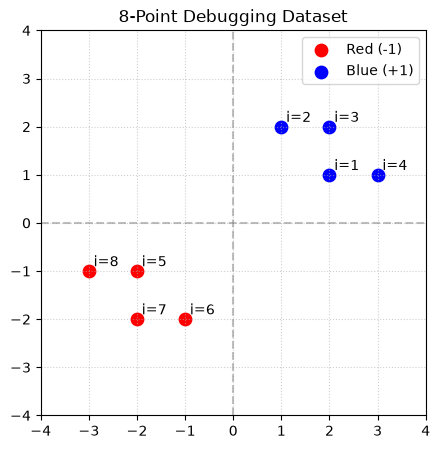

In [53]:
plt.figure(figsize=(5, 5))
plt.scatter(X_toy[y_toy == -1, 0], X_toy[y_toy == -1, 1], c='red', s=80, label='Red (-1)')
plt.scatter(X_toy[y_toy == 1, 0], X_toy[y_toy == 1, 1], c='blue', s=80, label='Blue (+1)')
for i, (x1, x2) in enumerate(X_toy, 1):
    plt.annotate(f'i={i}', (x1 + 0.1, x2 + 0.1))
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.gca().set_aspect('equal')
plt.title('8-Point Debugging Dataset')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

#### Visual Check: test06.bmp
Display original image on its coordinate system.

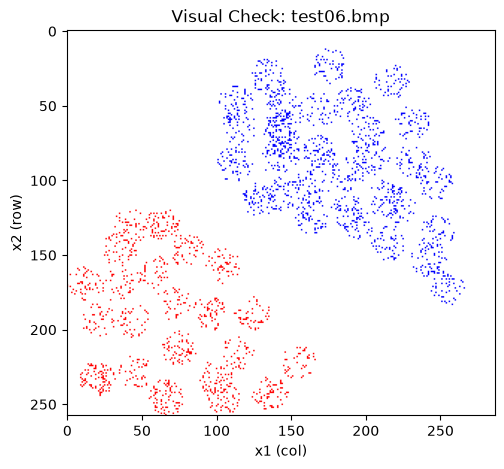

In [54]:
path_06 = os.path.join('data', 'test06.bmp') if os.path.exists(os.path.join('data', 'test06.bmp')) else 'test06.bmp'
img06 = Image.open(path_06)

plt.figure(figsize=(6, 5))
plt.imshow(img06)
plt.title('Visual Check: test06.bmp')
plt.xlabel('x1 (col)')
plt.ylabel('x2 (row)')
plt.show()

## 3. Part A — Implement the Perceptron from scratch
### 3.1 Task 1 — Prediction: score versus decision
- Signed score: $z_i = \mathbf{w}^T \mathbf{x}_i + b$
- Decision rule:
$$\hat{y}_i = \begin{cases} +1, & z_i \ge 0 \\ -1, & z_i < 0 \end{cases}$$
- Training margin: an example triggers an update whenever $y_i z_i \le 0$.

In [55]:
def predict_perceptron(X, w, b):
    z = X @ w + b
    return np.where(z >= 0, 1, -1)

#### Checkpoint A1 Verification
With $\mathbf{w} = (1, -1)^T$ and $b = 0$:
- $\mathbf{x} = (2, 1)^T \implies z = 1$ and $\hat{y} = +1$
- $\mathbf{x} = (1, 2)^T \implies z = -1$ and $\hat{y} = -1$
- $\mathbf{x} = (1, 1)^T \implies z = 0$ and $\hat{y} = +1$

In [56]:
w_test = np.array([1, -1], float)
b_test = 0.0
X_test = np.array([[2, 1], [1, 2], [1, 1]], float)

z_vals = X_test @ w_test + b_test
preds = predict_perceptron(X_test, w_test, b_test)

for x, z, y_hat in zip(X_test, z_vals, preds):
    print(f"x = {x} -> z = {z:+.0f}, y_hat = {y_hat:+d}")

x = [2. 1.] -> z = +1, y_hat = +1
x = [1. 2.] -> z = -1, y_hat = -1
x = [1. 1.] -> z = +0, y_hat = +1


### 3.2 Task 2 — One update, by hand
Update rule when margin $y_i z_i \le 0$ (with $\eta = 1$):
$$\mathbf{w} \leftarrow \mathbf{w} + \eta y_i \mathbf{x}_i, \quad b \leftarrow b + \eta y_i$$
Otherwise, do nothing.

In [57]:
# Trace of Epoch 1 and Epoch 2 on the 8 toy points
w = np.zeros(2)
b = 0.0
eta = 1.0

for epoch in [1, 2]:
    updates = 0
    print(f"--- Epoch {epoch} ---")
    for i in range(len(X_toy)):
        xi = X_toy[i]
        yi = y_toy[i]
        z = np.dot(w, xi) + b
        margin = yi * z

        if margin <= 0:
            w += eta * yi * xi
            b += eta * yi
            updates += 1
            print(f"Point {i+1} (x={xi}, y={yi:+d}): margin={margin:.1f} <= 0 -> UPDATE -> w={w}, b={b}")
        else:
            print(f"Point {i+1} (x={xi}, y={yi:+d}): margin={margin:.1f} > 0  -> no update")

    print(f"Epoch {epoch} finished with {updates} updates.")

--- Epoch 1 ---
Point 1 (x=[2. 1.], y=+1): margin=0.0 <= 0 -> UPDATE -> w=[2. 1.], b=1.0
Point 2 (x=[1. 2.], y=+1): margin=5.0 > 0  -> no update
Point 3 (x=[2. 2.], y=+1): margin=7.0 > 0  -> no update
Point 4 (x=[3. 1.], y=+1): margin=8.0 > 0  -> no update
Point 5 (x=[-2. -1.], y=-1): margin=4.0 > 0  -> no update
Point 6 (x=[-1. -2.], y=-1): margin=3.0 > 0  -> no update
Point 7 (x=[-2. -2.], y=-1): margin=5.0 > 0  -> no update
Point 8 (x=[-3. -1.], y=-1): margin=6.0 > 0  -> no update
Epoch 1 finished with 1 updates.
--- Epoch 2 ---
Point 1 (x=[2. 1.], y=+1): margin=6.0 > 0  -> no update
Point 2 (x=[1. 2.], y=+1): margin=5.0 > 0  -> no update
Point 3 (x=[2. 2.], y=+1): margin=7.0 > 0  -> no update
Point 4 (x=[3. 1.], y=+1): margin=8.0 > 0  -> no update
Point 5 (x=[-2. -1.], y=-1): margin=4.0 > 0  -> no update
Point 6 (x=[-1. -2.], y=-1): margin=3.0 > 0  -> no update
Point 7 (x=[-2. -2.], y=-1): margin=5.0 > 0  -> no update
Point 8 (x=[-3. -1.], y=-1): margin=6.0 > 0  -> no update
Epoch 

#### Checkpoint A2 Verification
- Epoch 1: Exactly 1 update occurs; final parameters: $\mathbf{w} = (2, 1)^T, b = 1$.
- Epoch 2: Exactly 0 updates occur (converged).

### 3.3 Task 3 — Complete training algorithm
Complete Perceptron training loop with early stopping when an epoch makes 0 updates.

In [58]:
def train_perceptron(X, y, eta=1.0, max_epochs=100, verbose=False):
    n, d = X.shape
    w = np.zeros(d, dtype=float)
    b = 0.0
    updates_history = []
    snapshots = [(w.copy(), b, "initial")]

    for epoch in range(1, max_epochs + 1):
        updates = 0
        for i in range(n):
            xi = X[i]
            yi = y[i]
            score = np.dot(w, xi) + b
            margin = yi * score

            if margin <= 0:
                w += eta * yi * xi
                b += eta * yi
                updates += 1
                snapshots.append((w.copy(), b, "after update"))

        updates_history.append(updates)
        if verbose:
            print(f"Epoch {epoch}: {updates} updates, w={w}, b={b}")

        if updates == 0:
            break

    return w, b, updates_history, snapshots

#### Checkpoint A3 Verification
- Run on 8 toy points (reproduce Checkpoint A2)
- Run on `test06.bmp` (converges in a few epochs)
- Run on `test01.bmp` with `max_epochs=100` (slow convergence expected due to coordinate scale)

In [59]:
# 1. 8 toy points
w_toy, b_toy, hist_toy, _ = train_perceptron(X_toy, y_toy, eta=1.0, max_epochs=10, verbose=True)
print("Toy updates history:", hist_toy)

# 2. test06.bmp
path_06 = os.path.join("data", "test06.bmp") if os.path.exists(os.path.join("data", "test06.bmp")) else "test06.bmp"
X06, y06, _ = load_bmp(path_06)
w06, b06, hist06, snaps06 = train_perceptron(X06, y06, eta=1.0, max_epochs=100)
print(f"test06.bmp: converged in {len(hist06)} epochs ({sum(hist06)} total updates), w={w06}, b={b06}")

# 3. test01.bmp
path_01 = os.path.join("data", "test01.bmp") if os.path.exists(os.path.join("data", "test01.bmp")) else "test01.bmp"
X01, y01, _ = load_bmp(path_01)
w01, b01, hist01, snaps01 = train_perceptron(X01, y01, eta=1.0, max_epochs=100)
print(f"test01.bmp: ran {len(hist01)} epochs, last epoch updates={hist01[-1]} (slow convergence expected)")

Epoch 1: 1 updates, w=[2. 1.], b=1.0
Epoch 2: 0 updates, w=[2. 1.], b=1.0
Toy updates history: [1, 0]
test06.bmp: converged in 2 epochs (2 total updates), w=[ 127. -108.], b=0.0
test01.bmp: ran 100 epochs, last epoch updates=8 (slow convergence expected)


### 3.4 Task 4 — Watch the boundary move
In 2D, the decision boundary is given by:
$$w_1 x_1 + w_2 x_2 + b = 0 \implies x_2 = -\frac{w_1 x_1 + b}{w_2} \quad (\text{if } w_2 \neq 0)$$
If $w_2 = 0$ and $w_1 \neq 0$, the line is vertical: $x_1 = -b / w_1$.

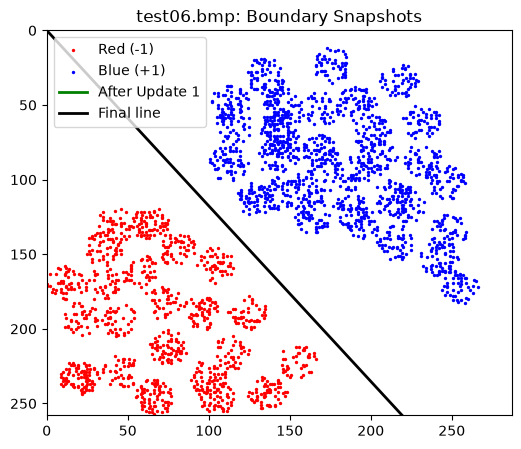

In [60]:
# 1. Plot test06 points and decision lines
x1 = np.array([0, 287])

plt.figure(figsize=(6, 5))
plt.scatter(X06[y06 == -1, 0], X06[y06 == -1, 1], c="red", s=2, label="Red (-1)")
plt.scatter(X06[y06 == 1, 0], X06[y06 == 1, 1], c="blue", s=2, label="Blue (+1)")

# Plot after first update and final line
for idx, label, color in [(1, "After Update 1", "green"), (-1, "Final line", "black")]:
    w, b, _ = snaps06[idx]
    plt.plot(x1, -(w[0] * x1 + b) / w[1], color=color, linewidth=2, label=label)

plt.xlim(0, 287)
plt.ylim(258, 0)
plt.legend()
plt.title("test06.bmp: Boundary Snapshots")
plt.show()

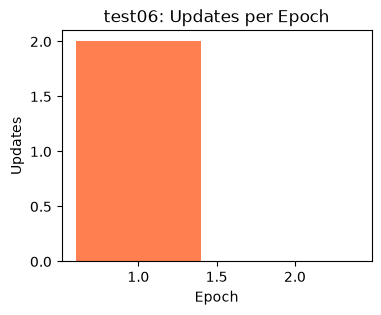

In [61]:
# 2. Updates per epoch
plt.figure(figsize=(4, 3))
plt.bar(range(1, len(hist06) + 1), hist06, color="coral")
plt.xlabel("Epoch")
plt.ylabel("Updates")
plt.title("test06: Updates per Epoch")
plt.show()

#### Verificare Checkpoint A4
- Snapshot-uri salvate: avem 3 in total (starea initiala + 2 update-uri), adica fix `sum(hist06) + 1`.
- Cand trece o epoca fara nicio greseala (0 update-uri), antrenarea se opreste.

#### Pe scurt, la intrebari:
1. **E linia asta singura varianta posibila?**
   Clar nu. Poti trasa o gramada de linii prin spatiul dintre rosu si albastru. Perceptronul e multumit cu prima linie pe care o nimereste si care nu greseste nimic. Nu sta sa o caute pe cea mai buna sau cea mai aerisita (cum face SVM-ul).

2. **Daca amestecam punctele in alta ordine, iese aceeasi linie?**
   Nu. El invata din mers, punct cu punct. Daca ii schimbi ordinea, greselile apar altfel, muta linia altfel si la final o sa se opreasca la o linie usor diferita.

3. **Daca nu a gresit nimic pe antrenare, suntem siguri ca merge bine si pe date noi?**
   Nici vorba. Doar pentru ca a nimerit tot ce i-ai aratat pana acum nu inseamna ca ghiceste viitorul. Daca linia trece la limita pe langa puncte sau daca datele noi pica putin mai intr-o parte, o sa greseasca usor.

## 4. Part B — Ready-made classifiers (test06.bmp)
Comparatie pe `test06.bmp`: Perceptron, k-NN (k=5), Linear SVM, Decision Tree (adancime 3).

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Split stratificat 75/25
X_tr, X_te, y_tr, y_te = train_test_split(X06, y06, test_size=0.25, stratify=y06, random_state=42)

# 2. Standardizare (folosind media si std de pe train)
mean, std = X_tr.mean(0), X_tr.std(0)
X_tr_s = (X_tr - mean) / std
X_te_s = (X_te - mean) / std

# 3. Antrenare modele
w_p, b_p, _, _ = train_perceptron(X_tr_s, y_tr, max_epochs=100)

models = {
    "Perceptron": None,
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5).fit(X_tr_s, y_tr),
    "Linear SVM": SVC(kernel="linear").fit(X_tr_s, y_tr),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_tr_s, y_tr)
}

# 4. Evaluare acuratete
print(f"{'Model':<15} | {'Train Acc':<10} | {'Test Acc':<10}")
print("-" * 40)

for name, m in models.items():
    if name == "Perceptron":
        tr_acc = np.mean(predict_perceptron(X_tr_s, w_p, b_p) == y_tr)
        te_acc = np.mean(predict_perceptron(X_te_s, w_p, b_p) == y_te)
    else:
        tr_acc = m.score(X_tr_s, y_tr)
        te_acc = m.score(X_te_s, y_te)
    print(f"{name:<15} | {tr_acc*100:>8.2f}% | {te_acc*100:>8.2f}%")

Model           | Train Acc  | Test Acc  
----------------------------------------
Perceptron      |   100.00% |    99.85%
k-NN (k=5)      |   100.00% |   100.00%
Linear SVM      |   100.00% |   100.00%
Decision Tree   |    99.95% |    99.85%


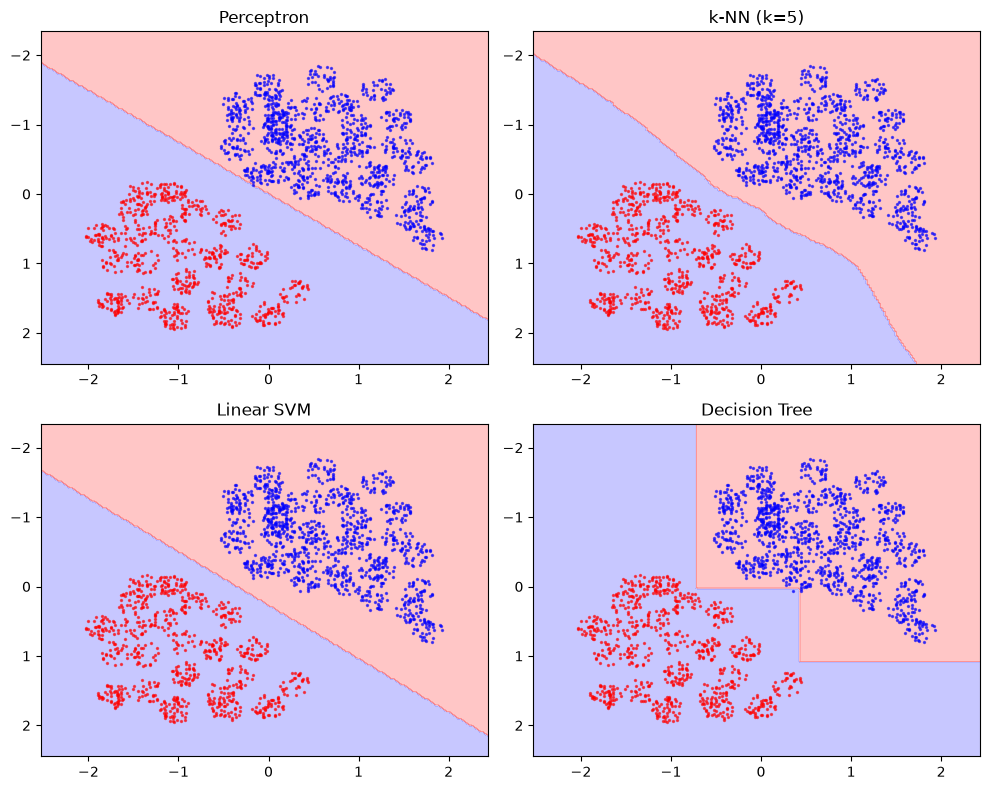

In [ ]:
# 5. Plot 4 panouri cu regiunile de decizie
x_min, x_max = X_tr_s[:, 0].min() - 0.5, X_tr_s[:, 0].max() + 0.5
y_min, y_max = X_tr_s[:, 1].min() - 0.5, X_tr_s[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, m) in zip(axes.ravel(), models.items()):
    if name == "Perceptron":
        Z = predict_perceptron(grid, w_p, b_p).reshape(xx.shape)
    else:
        Z = m.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="bwr")
    ax.scatter(X_tr_s[y_tr == -1, 0], X_tr_s[y_tr == -1, 1], c="red", s=2, alpha=0.6)
    ax.scatter(X_tr_s[y_tr == 1, 0], X_tr_s[y_tr == 1, 1], c="blue", s=2, alpha=0.6)
    ax.set_title(name)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_max, y_min)  # pastram orientarea coordonatelor imagine

plt.tight_layout()
plt.show()

#### Checkpoint B & Discutie
- **Forma granitelor:**
  - *Perceptron & Linear SVM:* linii drepte.
  - *Decision Tree:* dreptunghiuri aliniate cu axele (taieturi perpendiculare pe $x_1$ si $x_2$).
  - *k-NN:* granita neregulata, urmareste forma punctelor locale.

- **Intrebari de discutie:**
  1. *O acuratete mai mare pe train inseamna neaparat un model mai bun?*
     Nu. Daca un model doar "toceste" datele de antrenare (overfitting), poate avea 100% pe train si sa dea gres pe date noi de test. Ne intereseaza acuratetea pe test (cat de bine generalizeaza).

  2. *De ce k-NN prezice diferit fata de Perceptron?*
     Perceptronul invata o linie fixa (ecuatie globala data de ponderile $w$ si $b$), dupa care uita complet datele de antrenare. k-NN este opusul: nu invata nicio formula, tine minte toate punctele si, cand vine un punct nou, doar cauta cei mai apropiati 5 vecini si alege clasa cu cele mai multe voturi.

## 5. Part C — A dataset that is not linearly separable (test07.bmp)
Cele doua clase formeaza doua semiluni intrepuse (two moons). O linie dreapta nu le poate separa complet.

In [64]:
# 1. Incarcare test07.bmp si split 75/25 stratificat
path_07 = "data/test07.bmp" if os.path.exists("data/test07.bmp") else "test07.bmp"
X07, y07, _ = load_bmp(path_07)

X_tr7, X_te7, y_tr7, y_te7 = train_test_split(X07, y07, test_size=0.25, stratify=y07, random_state=42)

# 2. Standardizare pe train
mean7, std7 = X_tr7.mean(0), X_tr7.std(0)
X_tr7_s = (X_tr7 - mean7) / std7
X_te7_s = (X_te7 - mean7) / std7

# 3. Antrenare modele (Perceptron, k-NN, RBF SVM, Decision Tree max_depth=5)
w_p7, b_p7, _, _ = train_perceptron(X_tr7_s, y_tr7, max_epochs=100)

models7 = {
    "Perceptron": None,
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5).fit(X_tr7_s, y_tr7),
    "RBF SVM": SVC(kernel="rbf").fit(X_tr7_s, y_tr7),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=0).fit(X_tr7_s, y_tr7)
}

# 4. Evaluare acuratete
print(f"{'Model':<15} | {'Train Acc':<10} | {'Test Acc':<10}")
print("-" * 40)

for name, m in models7.items():
    if name == "Perceptron":
        tr_acc = np.mean(predict_perceptron(X_tr7_s, w_p7, b_p7) == y_tr7)
        te_acc = np.mean(predict_perceptron(X_te7_s, w_p7, b_p7) == y_te7)
    else:
        tr_acc = m.score(X_tr7_s, y_tr7)
        te_acc = m.score(X_te7_s, y_te7)
    print(f"{name:<15} | {tr_acc*100:>8.2f}% | {te_acc*100:>8.2f}%")

Model           | Train Acc  | Test Acc  
----------------------------------------
Perceptron      |    83.67% |    84.13%
k-NN (k=5)      |   100.00% |   100.00%
RBF SVM         |    99.36% |    99.37%
Decision Tree   |    98.62% |    97.78%


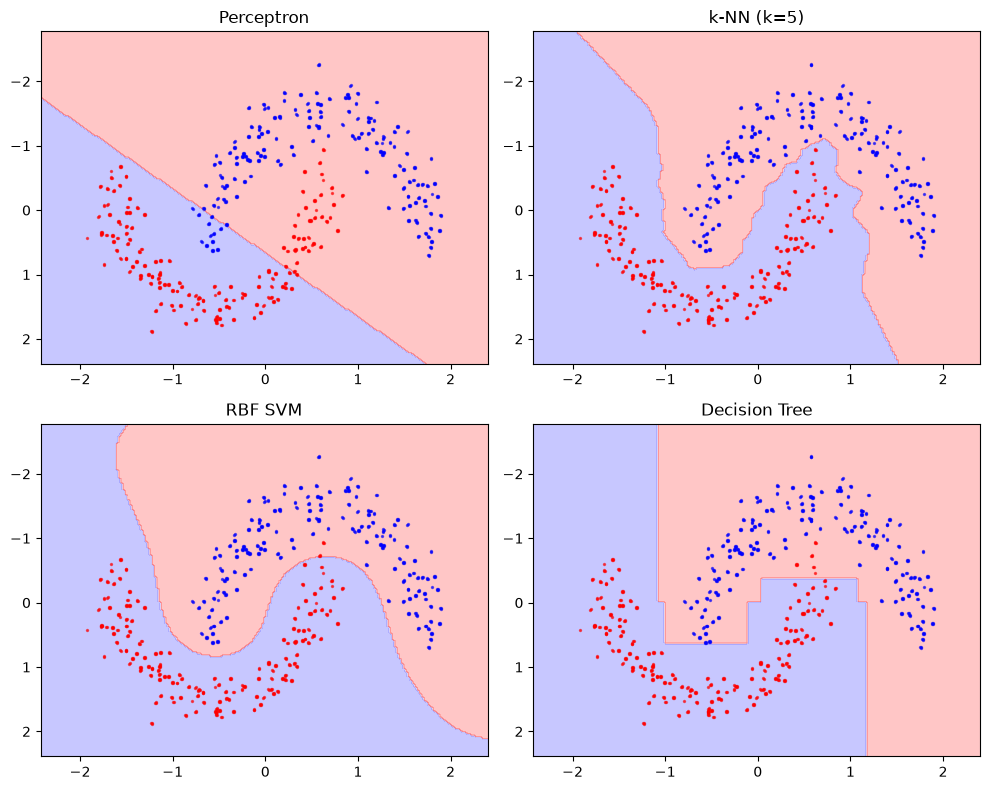

In [ ]:
# 5. Plot 4 panouri cu regiunile de decizie pe test07
x_min, x_max = X_tr7_s[:, 0].min() - 0.5, X_tr7_s[:, 0].max() + 0.5
y_min, y_max = X_tr7_s[:, 1].min() - 0.5, X_tr7_s[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, (name, m) in zip(axes.ravel(), models7.items()):
    if name == "Perceptron":
        Z = predict_perceptron(grid, w_p7, b_p7).reshape(xx.shape)
    else:
        Z = m.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="bwr")
    ax.scatter(X_tr7_s[y_tr7 == -1, 0], X_tr7_s[y_tr7 == -1, 1], c="red", s=2, alpha=0.6)
    ax.scatter(X_tr7_s[y_tr7 == 1, 0], X_tr7_s[y_tr7 == 1, 1], c="blue", s=2, alpha=0.6)
    ax.set_title(name)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_max, y_min)  # orientare imagine

plt.tight_layout()
plt.show()

#### Checkpoint C & Raspunsuri la intrebari
1. **De ce nu poate Perceptronul sa clasifice corect toate punctele, oricate epoci i-am da?**
   Pentru ca Perceptronul este strict un model liniar: el poate trasa doar o linie dreapta. Datele au forma a doua semiluni curbate si incolacite, deci nicio linie dreapta din lume nu le poate separa fara sa taie prin ele.

2. **Cum difera granita RBF SVM fata de cea a unui SVM liniar?**
   SVM-ul liniar ar trage tot o dreapta (ca Perceptronul). RBF SVM foloseste un nucleu neliniar care ii permite sa indoaie granita si sa deseneze o curba lina, mulata perfect dupa forma semilunilor.

3. **Cum aproximeaza k-NN si Decision Tree o curba?**
   - **k-NN:** ia decizii strict local, uitandu-se la cei mai apropiati 5 vecini ai fiecarui punct. Asa reuseste sa urmareasca orice forma serpuita.
   - **Decision Tree:** stie sa faca doar taieturi perpendiculare pe axe ($x_1 < c$ sau $x_2 < c$). Ca sa ocoleasca o curba, imbina multe bucati dreptunghiulare, formand o granita in trepte (in zig-zag).

4. **Care model a avut cel mai bun rezultat pe test? A avut si cel mai mare scor pe train?**
   k-NN a avut cel mai bun scor (100% pe test si 100% pe train), secondat indeaproape de RBF SVM (~99.4%). Ambele modele neliniare au reusit sa desparta usor semilunile, spre deosebire de Perceptron care a ramas blocat la ~84%.